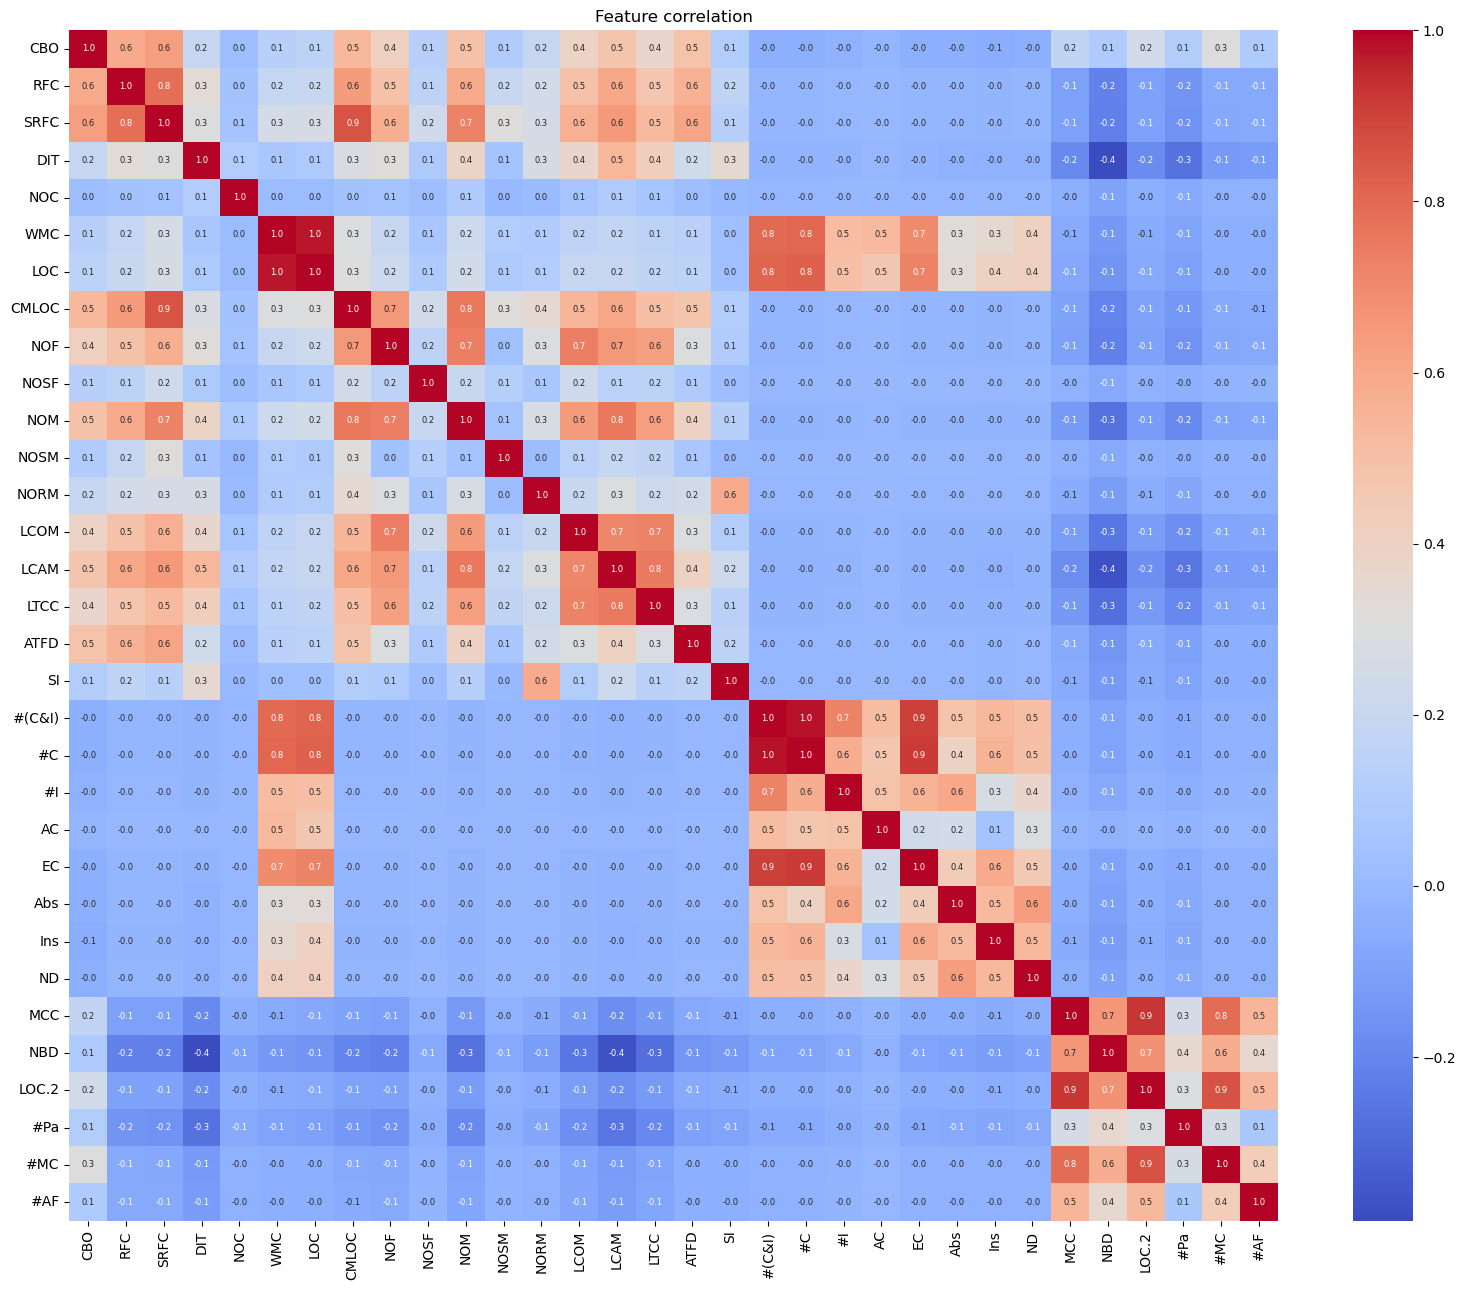

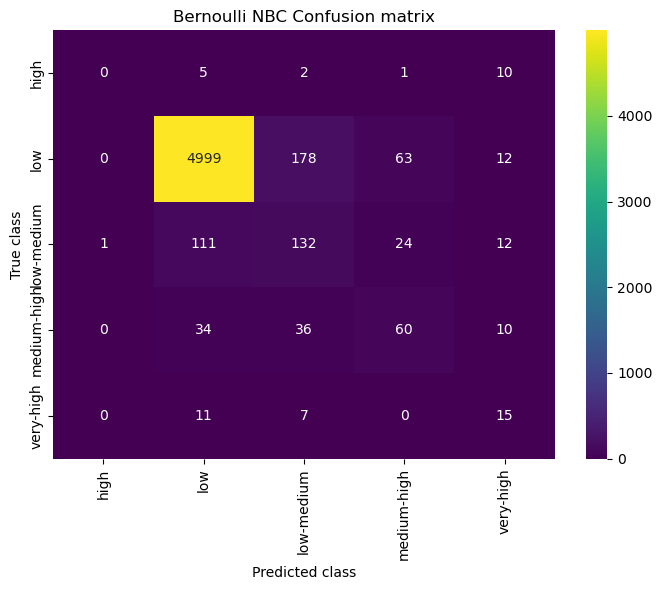

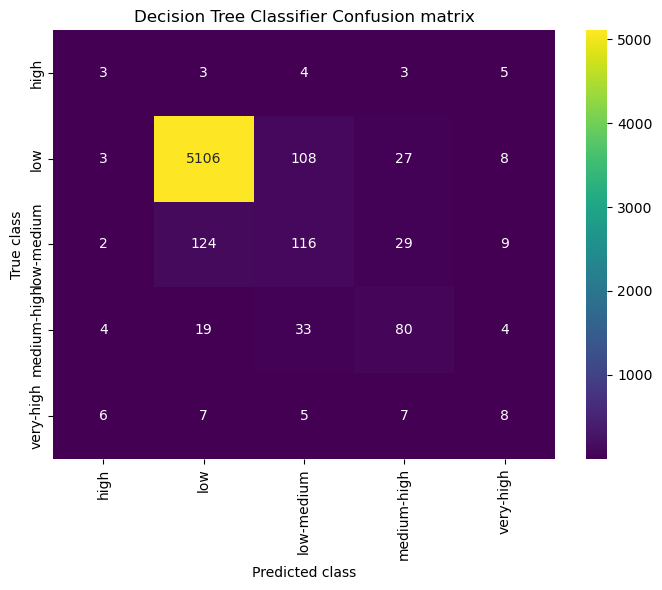

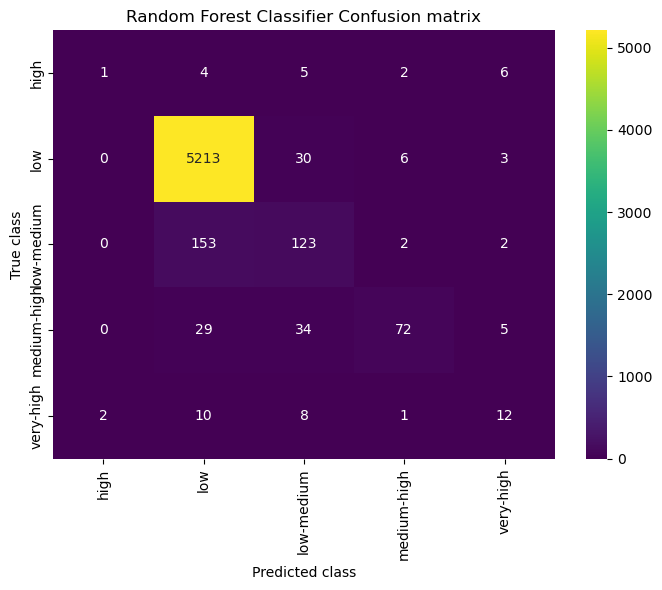

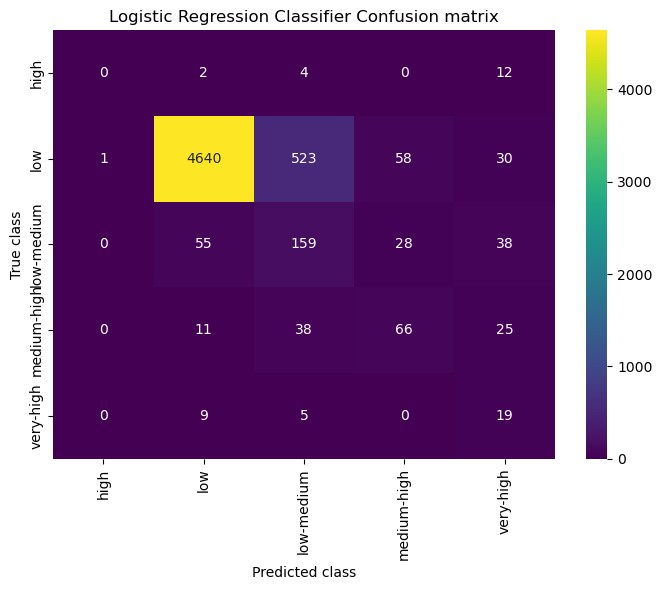

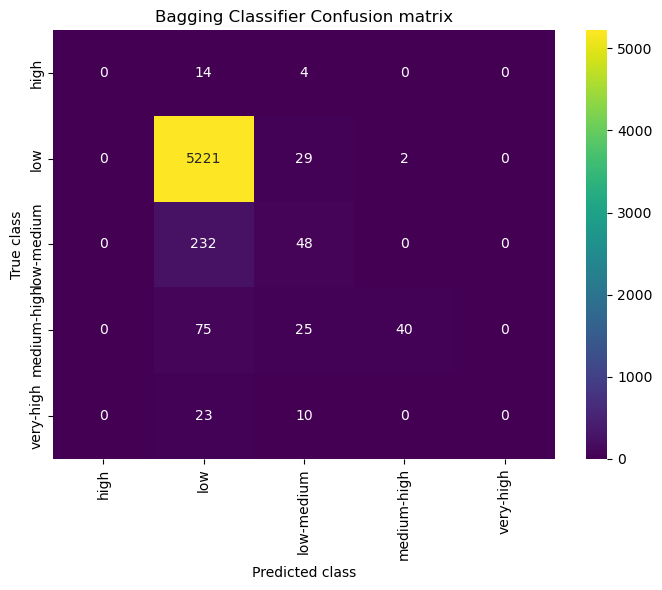

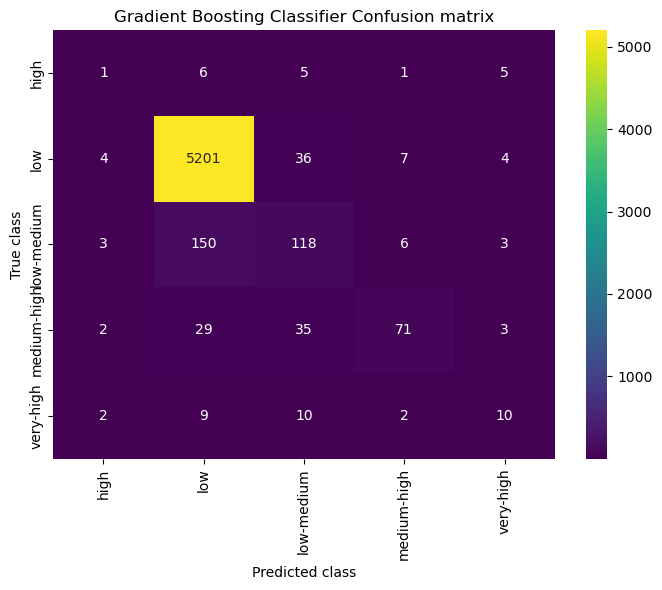

C:\Users\prahu\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9190 - loss: 0.2392 - val_accuracy: 0.9238 - val_loss: 0.1746
Epoch 2/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9283 - loss: 0.1769 - val_accuracy: 0.9312 - val_loss: 0.1617
Epoch 3/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9301 - loss: 0.1685 - val_accuracy: 0.9380 - val_loss: 0.1543
Epoch 4/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9318 - loss: 0.1638 - val_accuracy: 0.9345 - val_loss: 0.1569
Epoch 5/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9335 - loss: 0.1633 - val_accuracy: 0.9357 - val_loss: 0.1498
Epoch 6/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9363 - loss: 0.1584 - val_accuracy: 0.9376 - val_loss: 0.1488
Epoch 7/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9354 - loss: 0.1563 - val_accuracy: 0.9381 - val_loss: 0.1456
Epoch 8/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9381 - loss: 0.1545 - val_accuracy: 0.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 512)                 │          15,872 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 512)                 │         262,656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │           2,565 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 5)                   │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 843,281 (3.22 MB)

 Trainable params: 281,093 (1.07 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 562,188 (2.14 MB)

179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


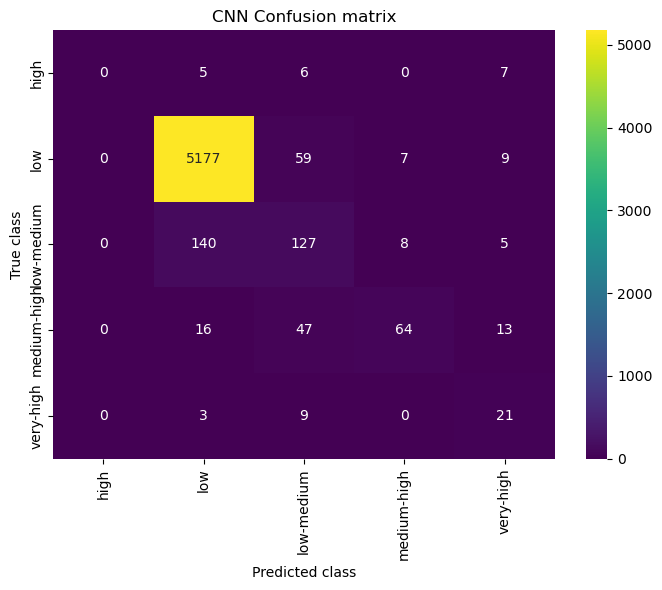

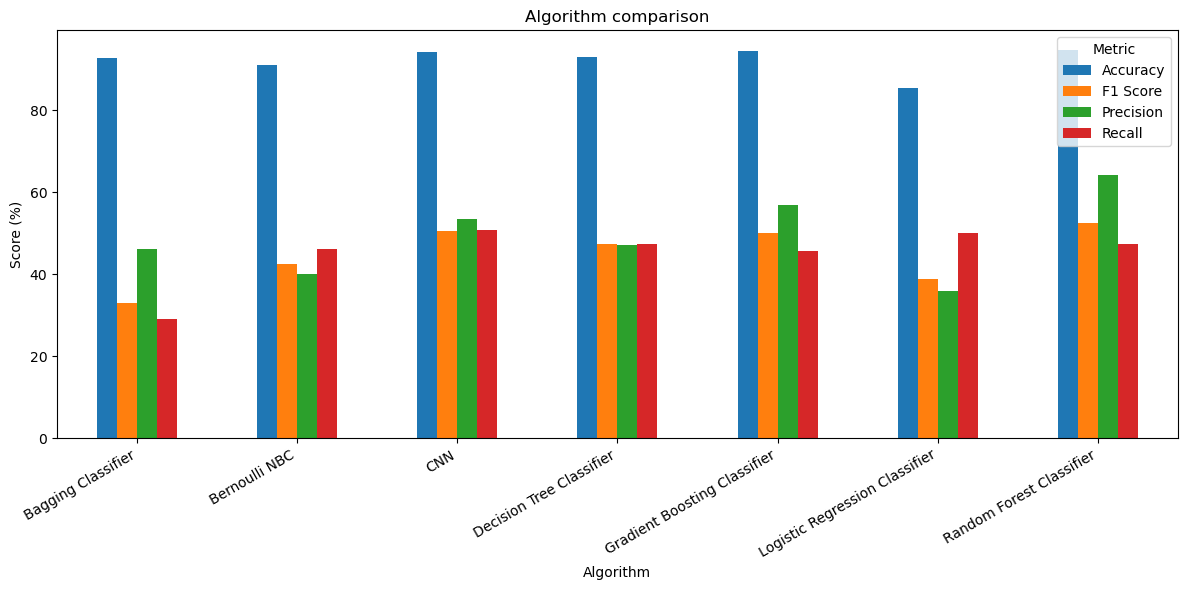

In [1]:
import tkinter
from tkinter import *
from tkinter import filedialog, messagebox
import os

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier,
                              GradientBoostingClassifier,
                              BaggingClassifier)
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, precision_score,
                             recall_score, f1_score)

try:
    from tensorflow.keras.utils import to_categorical
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Dense, Dropout, Activation
except ImportError:
    from keras.utils import to_categorical
    from keras.models import Sequential
    from keras.layers import Dense, Dropout, Activation

# ---------------------------------------------------------------- GUI window
main = tkinter.Tk()
main.title("Classification App")
screen_width = main.winfo_screenwidth()
screen_height = main.winfo_screenheight()
main.geometry(f"{screen_width}x{screen_height}")

# ------------------------------------------------------------ global state
dataset = None            # raw CSV as loaded
features_df = None        # cleaned numeric feature table
X = Y = None
X_train = X_test = y_train = y_test = None
pca = None
le = None                 # LabelEncoder for the target
feature_cols = None       # feature names used in training (needed for prediction)
categories = []           # class names, filled from the data (NOT hard-coded)
trained_models = {}       # name -> fitted sklearn model
results = {}              # name -> metrics dict (one entry per algorithm)

LABEL_COL = 'Complexity'                      # target to predict
LABEL_COLS = ['Complexity', 'Coupling', 'Size', 'Lack of Cohesion']
TEXT_COLS = ['QualifiedName', 'Name']
DUPLICATE_COLS = ['LOC.1', 'WMC.1']           # exact copies of LOC and WMC


# ------------------------------------------------------------ helpers
def clean_dataframe(df):
    """Fix the data problems found in the CSV."""
    df = df.copy()
    df.columns = df.columns.str.replace('\ufeff', '', regex=False).str.strip()

    if 'QualifiedName' in df.columns:
        qn = df['QualifiedName'].astype(str)
        # junk rows: project-name row and the bare "<Package>" row
        df = df[~qn.str.startswith('spring-framework') & (qn != '<Package>')]

    df = df.drop_duplicates()

    if 'NBD' in df.columns:                   # -2147483648 is an overflow value
        df.loc[df['NBD'] < 0, 'NBD'] = np.nan

    df = df.drop(columns=[c for c in DUPLICATE_COLS if c in df.columns])
    return df


def build_features(df):
    """Numeric features only: no text columns, no label columns (avoids leakage)."""
    drop = [c for c in TEXT_COLS + LABEL_COLS if c in df.columns]
    feats = df.drop(columns=drop)
    feats = feats.apply(pd.to_numeric, errors='coerce').fillna(0)
    return feats


def ready(condition, message):
    if not condition:
        messagebox.showwarning("Step missing", message)
        return False
    return True


# ------------------------------------------------------------ GUI actions
def uploadDataset():
    global dataset, features_df, X, Y, X_train, X_test, y_train, y_test
    filename = filedialog.askopenfilename(initialdir=".", filetypes=[("CSV files", "*.csv")])
    if not filename:
        return
    text.delete('1.0', END)
    dataset = pd.read_csv(filename, encoding='utf-8-sig')   # utf-8-sig removes the BOM
    # reset everything downstream of a new dataset
    features_df = X = Y = X_train = X_test = y_train = y_test = None
    trained_models.clear()
    results.clear()
    text.insert(END, filename + " loaded\n\n")
    text.insert(END, "Shape: " + str(dataset.shape) + "\n\n")
    text.insert(END, dataset.head().to_string())            # head() needs the brackets


def preprocess():
    global X, Y, categories, le, feature_cols, features_df
    if not ready(dataset is not None, "Upload the dataset first."):
        return
    text.delete('1.0', END)

    df = clean_dataframe(dataset)                           # does not modify `dataset`
    if LABEL_COL not in df.columns:
        messagebox.showerror("Error", f"Column '{LABEL_COL}' not found in the CSV.")
        return
    df = df.dropna(subset=[LABEL_COL]).reset_index(drop=True)   # keep labelled rows only

    le = LabelEncoder()
    Y = le.fit_transform(df[LABEL_COL].astype(str))
    categories = list(le.classes_)                          # same order as the encoded ids

    features_df = build_features(df)
    feature_cols = list(features_df.columns)
    X = normalize(features_df.values)

    text.insert(END, f"Rows after cleaning: {len(df)}\n")
    text.insert(END, f"Features used: {len(feature_cols)}\n")
    text.insert(END, "Labels found in dataset are: " + str(categories) + "\n")
    text.insert(END, "Class counts:\n" + df[LABEL_COL].value_counts().to_string() + "\n\n")
    text.insert(END, str(X) + "\n")


def featureSelection():
    global X, pca, X_train, X_test, y_train, y_test
    if not ready(X is not None, "Run 'Preprocess Dataset' first."):
        return
    text.delete('1.0', END)
    text.insert(END, "Total features before PCA = " + str(X.shape[1]) + "\n")

    n_comp = min(30, X.shape[1])
    pca = PCA(n_components=n_comp)
    X_pca = pca.fit_transform(X)
    text.insert(END, "Total features after PCA  = " + str(X_pca.shape[1]) + "\n")

    try:
        X_train, X_test, y_train, y_test = train_test_split(
            X_pca, Y, test_size=0.2, random_state=42, stratify=Y)
    except ValueError:                                      # a class is too small to stratify
        X_train, X_test, y_train, y_test = train_test_split(
            X_pca, Y, test_size=0.2, random_state=42)

    text.insert(END, "Total records            : " + str(X_pca.shape[0]) + "\n")
    text.insert(END, "Records used for training: " + str(X_train.shape[0]) + "\n")
    text.insert(END, "Records used for testing : " + str(X_test.shape[0]) + "\n")

    plt.figure(figsize=(16, 13))
    sns.heatmap(features_df.corr(), annot=True, fmt=".1f", annot_kws={"size": 6},
                cmap="coolwarm")
    plt.title("Feature correlation")
    plt.tight_layout()
    plt.show()


def Calculate_Metrics(algorithm, predict, y_true):
    labels = list(range(len(categories)))

    a = accuracy_score(y_true, predict) * 100
    p = precision_score(y_true, predict, average='macro', zero_division=0) * 100
    r = recall_score(y_true, predict, average='macro', zero_division=0) * 100
    f = f1_score(y_true, predict, average='macro', zero_division=0) * 100

    results[algorithm] = {'Accuracy': a, 'Precision': p, 'Recall': r, 'F1 Score': f}

    text.insert(END, f"{algorithm} Accuracy  : {a:.2f}\n")
    text.insert(END, f"{algorithm} Precision : {p:.2f}\n")
    text.insert(END, f"{algorithm} Recall    : {r:.2f}\n")
    text.insert(END, f"{algorithm} FScore    : {f:.2f}\n\n")

    # labels= makes the report work even if a class is missing from the test set
    CR = classification_report(y_true, predict, labels=labels,
                               target_names=categories, zero_division=0)
    text.insert(END, algorithm + " Classification Report\n")
    text.insert(END, CR + "\n\n")

    conf_matrix = confusion_matrix(y_true, predict, labels=labels)
    plt.figure(figsize=(7, 6))
    sns.heatmap(conf_matrix, xticklabels=categories, yticklabels=categories,
                annot=True, cmap="viridis", fmt="g")
    plt.title(algorithm + " Confusion matrix")
    plt.ylabel('True class')
    plt.xlabel('Predicted class')
    plt.tight_layout()
    plt.show()


def run_model(name, model):
    if not ready(X_train is not None, "Run 'PCA Features Selection' first."):
        return
    text.delete('1.0', END)
    text.insert(END, f"Training {name} ... please wait\n")
    main.update_idletasks()

    model.fit(X_train, y_train)                             # train on TRAIN data
    predict = model.predict(X_test)                         # evaluate on TEST data
    trained_models[name] = model

    text.delete('1.0', END)
    Calculate_Metrics(name, predict, y_test)


def runML1():
    run_model("Bernoulli NBC", BernoulliNB(binarize=0.0))


def runML2():
    run_model("Decision Tree Classifier",
              DecisionTreeClassifier(class_weight='balanced', random_state=0))


def runML3():
    run_model("Random Forest Classifier",
              RandomForestClassifier(class_weight='balanced', random_state=0, n_jobs=-1))


def runML4():
    run_model("Logistic Regression Classifier",
              LogisticRegression(C=0.01, penalty='l1', solver='liblinear',
                                 class_weight='balanced'))


def runML5():
    # sklearn >= 1.2 renamed base_estimator -> estimator
    # max_samples keeps SVC fast on a large dataset
    try:
        model = BaggingClassifier(estimator=SVC(), n_estimators=10,
                                  max_samples=0.2, random_state=0)
    except TypeError:
        model = BaggingClassifier(base_estimator=SVC(), n_estimators=10,
                                  max_samples=0.2, random_state=0)
    run_model("Bagging Classifier", model)


def runML6():
    run_model("Gradient Boosting Classifier", GradientBoostingClassifier(random_state=0))


def runCNN():
    if not ready(X_train is not None, "Run 'PCA Features Selection' first."):
        return
    text.delete('1.0', END)
    text.insert(END, "Training deep learning model ... please wait\n")
    main.update_idletasks()

    n_classes = len(categories)                             # not hard-coded to 6
    y_train_cat = to_categorical(y_train, num_classes=n_classes)
    y_test_cat = to_categorical(y_test, num_classes=n_classes)

    cnn_model = Sequential()
    cnn_model.add(Dense(512, input_shape=(X_train.shape[1],)))
    cnn_model.add(Activation('relu'))
    cnn_model.add(Dropout(0.3))
    cnn_model.add(Dense(512))
    cnn_model.add(Activation('relu'))
    cnn_model.add(Dropout(0.3))
    cnn_model.add(Dense(n_classes))
    cnn_model.add(Activation('softmax'))
    cnn_model.compile(loss='categorical_crossentropy', optimizer='adam',
                      metrics=['accuracy'])
    cnn_model.fit(X_train, y_train_cat, epochs=10, batch_size=64,
                  validation_data=(X_test, y_test_cat), verbose=1)   # fit on TRAIN data
    cnn_model.summary()

    predict = np.argmax(cnn_model.predict(X_test), axis=1)
    text.delete('1.0', END)
    Calculate_Metrics("CNN", predict, y_test)


def Prediction():
    if not ready(trained_models, "Train at least one ML model first."):
        return

    # use the model with the best F1 score so far
    best = max(trained_models, key=lambda n: results.get(n, {}).get('F1 Score', 0))
    model = trained_models[best]

    filename = filedialog.askopenfilename(initialdir=".", filetypes=[("CSV files", "*.csv")])
    if not filename:
        return
    text.delete('1.0', END)
    text.insert(END, f"{filename} loaded\nUsing model: {best}\n\n")

    new = pd.read_csv(filename, encoding='utf-8-sig')
    new = clean_dataframe(new)
    if 'QualifiedName' in new.columns:                      # <Field> rows have no metrics
        new = new[~new['QualifiedName'].astype(str).str.startswith('<Field>')]
    new = new.reset_index(drop=True)

    # SAME columns and SAME fitted PCA as training. Use transform(), never fit_transform().
    feats = build_features(new).reindex(columns=feature_cols, fill_value=0)
    Xn = pca.transform(normalize(feats.values))
    predicted = model.predict(Xn).astype(int)
    labels = [categories[i] for i in predicted]

    out = pd.DataFrame({
        'QualifiedName': new['QualifiedName'] if 'QualifiedName' in new.columns else new.index,
        'Predicted': labels})
    if LABEL_COL in new.columns:
        out['Actual'] = new[LABEL_COL]

    save_path = os.path.splitext(filename)[0] + "_predictions.csv"
    out.to_csv(save_path, index=False)

    text.insert(END, f"Predictions for {len(out)} rows (first 300 shown, all saved to):\n{save_path}\n\n")
    text.insert(END, out.head(300).to_string() + "\n")


def graph():
    if not ready(results, "Run at least one algorithm first."):
        return
    rows = [[algo, metric, value]
            for algo, m in results.items() for metric, value in m.items()]
    df = pd.DataFrame(rows, columns=['Algorithm', 'Metric', 'Value'])
    ax = df.pivot(index='Algorithm', columns='Metric', values='Value').plot(
        kind='bar', figsize=(12, 6))
    ax.set_ylabel("Score (%)")
    plt.xticks(rotation=30, ha='right')
    plt.title("Algorithm comparison")
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------ widgets
font = ('times', 18, 'bold')
title = Label(main, text="Reimagining System Efficiency using Software Engineering Paradigm with ML Integration")
title.config(bg='thistle2', fg='black', font=font, height=3, width=120)
title.pack()

font1 = ('times', 13, 'bold')
buttons = [
    ("Upload Dataset", uploadDataset),
    ("Preprocess Dataset", preprocess),
    ("PCA Features Selection", featureSelection),
    ("Bernoulli NBC", runML1),
    ("Decision Tree Classifier", runML2),
    ("Random Forest Classifier", runML3),
    ("Logistic Regression Classifier", runML4),
    ("Bagging Classifier", runML5),
    ("Gradient Boosting Classifier", runML6),
    ("DL CNN", runCNN),
    ("Comparison Graph", graph),
    ("Prediction", Prediction),
]
for i, (label, command) in enumerate(buttons):
    b = Button(main, text=label, command=command, font=font1)
    b.place(x=1250, y=100 + 50 * i)

font2 = ('times', 12, 'bold')
frame = Frame(main)
frame.place(x=45, y=100)
scroll = Scrollbar(frame)
scroll.pack(side=RIGHT, fill=Y)
text = Text(frame, height=30, width=140, font=font2, yscrollcommand=scroll.set)
text.pack(side=LEFT)
scroll.config(command=text.yview)

main.config(bg='SlateBlue1')
main.mainloop()          # ONLY ONE mainloop, and it must be the LAST line